In [11]:
import os
import subprocess as sp
import json
from urllib.request import Request, urlopen
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool
load_dotenv()

# os.environ["LANG_SEARCH_API_KEY"] = os.getenv("LANG_SEARCH_API_KEY")
LANG_SEARCH_API_KEY = os.getenv("LANG_SEARCH_API_KEY")
os.environ["GEMINI_API_KEY"] = os.getenv("GEMINI_API_KEY")

model = init_chat_model(
    model="gemini-3.1-flash-lite",
    model_provider="google_genai"
)


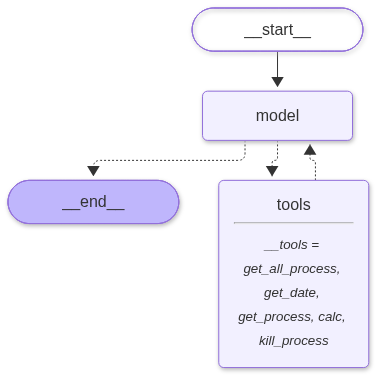

In [24]:
import ssl
import certifi

@tool
def internet_search_tool(query:str, result_count:int = 5)->str:
    """Get the information from the internet"""
    request = Request(
    "https://api.langsearch.com/v1/web-search",
    data=json.dumps({
        "query": f"{query}",
        "count": result_count, "contents": {"text": True}, "freshness": "noLimit"
    }).encode(),
    headers={
        "Authorization": f"Bearer {LANG_SEARCH_API_KEY}",
        "Content-Type": "application/json"
    }
    )
    # with urlopen(request, timeout=30) as response:
    #     return json.load(response)

    #If get SSLCertVerificationError
    ssl_context = ssl.create_default_context(cafile=certifi.where())

    with urlopen(request, timeout=30, context=ssl_context) as response:
        return json.load(response)
    
    # for source in result["data"]["webPages"]["value"]:
    #     print(source["name"], source["url"])


@tool
def calc(expression:str)->str:
    """Evaluate Mathematical expression"""
    return str(eval(expression))


from langchain.tools import tool

@tool
def get_date()->str:
    """Get the current local system date."""
    return sp.run(["date"],capture_output=True, text=True)


@tool
def get_all_process() -> str:
    """List processes associated with terminals across all users."""
    result = sp.run(["ps", "-a"], capture_output=True, text=True)
    return result.stdout


@tool
def get_process() -> str:
    """List processes associated with the current user's terminal."""
    result = sp.run(["ps"], capture_output=True, text=True)
    return result.stdout


@tool
def kill_process(pid:str) -> str:
    """Kill the process of given pid."""

    #For security
    desired_pid = "63972" #Replace this pid with the pid, you targeted to kill
    if pid != desired_pid:
        return "[Failed] Unable to kill the process...."
    
    result = sp.run(["kill",f"{pid}"], capture_output=True, text=True)
    return result



agent = create_agent(
    model=model,
    tools=[get_all_process, get_date, get_process, calc, kill_process]
    )
agent


In [4]:
res = internet_search_tool.invoke({"query":"give the latest news about gta6"})
print(res)

{'code': 200, 'log_id': '277d6aa31479e45e', 'msg': None, 'data': {'_type': 'SearchResponse', 'queryContext': {'originalQuery': 'give the latest news about gta6'}, 'webPages': {'webSearchUrl': 'https://langsearch.com/search?q=give+the+latest+news+about+gta6', 'totalEstimatedMatches': None, 'value': [{'id': 'results.#0', 'name': 'GTA 6 LIVE: Official game updates imminent from Take-Two Interactive', 'url': 'https://www.indy100.com/gaming/gta-6-preorder-preload-release', 'displayUrl': 'https://www.indy100.com/gaming/gta-6-preorder-preload-release', 'text': "GTA 6 LIVE: Official game updates imminent from Take-Two Interactive\n\nGTA 6 official updates will soon be shared by Take-Two Interactive as Rockstar Games' parent company hosts a quarterly earnings call.\n\nGrand Theft Auto 6 releases next week on 19 November on PS5 and XBOX Series X/S.\n\nThose who pre-order the Standard or Ultimate Edition can pre-load GTA 6 in advance from 10 November, with game size and release time details also 

In [8]:
res['data']

{'_type': 'SearchResponse',
 'queryContext': {'originalQuery': 'give the latest news about gta6'},
 'webPages': {'webSearchUrl': 'https://langsearch.com/search?q=give+the+latest+news+about+gta6',
  'totalEstimatedMatches': None,
  'value': [{'id': 'results.#0',
    'name': 'GTA 6 LIVE: Official game updates imminent from Take-Two Interactive',
    'url': 'https://www.indy100.com/gaming/gta-6-preorder-preload-release',
    'displayUrl': 'https://www.indy100.com/gaming/gta-6-preorder-preload-release',
    'text': "GTA 6 LIVE: Official game updates imminent from Take-Two Interactive\n\nGTA 6 official updates will soon be shared by Take-Two Interactive as Rockstar Games' parent company hosts a quarterly earnings call.\n\nGrand Theft Auto 6 releases next week on 19 November on PS5 and XBOX Series X/S.\n\nThose who pre-order the Standard or Ultimate Edition can pre-load GTA 6 in advance from 10 November, with game size and release time details also being recently revealed by Rockstar.\n\nFol

In [14]:
user_input="Give the sum of the pid of the processes associated with the current user's terminal. "

for chunk in agent.stream({"messages": user_input}, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

Give the sum of the pid of the processes associated with the current user's terminal. 
================================== Ai Message ==================================

[]
Tool Calls:
  get_process (call_16822070633708736437)
 Call ID: call_16822070633708736437
  Args:
================================= Tool Message =================================
Name: get_process

  PID TTY           TIME CMD
 1693 ttys001    0:00.13 /bin/zsh -il
 1694 ttys002    0:00.13 /bin/zsh -il
 1767 ttys003    0:00.40 /bin/zsh -il
 1768 ttys004    0:00.37 /bin/zsh -il
 1945 ttys005    0:00.03 /bin/zsh -i

================================== Ai Message ==================================

[]
Tool Calls:
  calc (call_17710302962405267801)
 Call ID: call_17710302962405267801
  Args:
    expression: 1693 + 1694 + 1767 + 1768 + 1945
================================= Tool Message =================================
Name: calc

8867
======

In [25]:
user_input="Give the sum of the pid of the processes associated with the current user's terminal. Then kill the process ollama if running"

for chunk in agent.stream({"messages": user_input}, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

Give the sum of the pid of the processes associated with the current user's terminal. Then kill the process ollama if running
================================== Ai Message ==================================

[]
Tool Calls:
  get_process (call_4237950894289677933)
 Call ID: call_4237950894289677933
  Args:
================================= Tool Message =================================
Name: get_process

  PID TTY           TIME CMD
 1693 ttys001    0:00.13 /bin/zsh -il
 1694 ttys002    0:00.13 /bin/zsh -il
 1767 ttys003    0:00.43 /bin/zsh -il
63972 ttys003    0:03.35 ollama
 1768 ttys004    0:00.44 /bin/zsh -il
 1945 ttys005    0:00.03 /bin/zsh -i

================================== Ai Message ==================================

[]
Tool Calls:
  calc (call_17485536836408228411)
 Call ID: call_17485536836408228411
  Args:
    expression: 1693 + 1694 + 1767 + 63972 + 1768 + 1945
===========================